# 31 - Modelo A: suscetibilidade a cheias (30 m)

| | |
|---|---|
| **Tarefa do plano** | S3-02 (Modelo A + mapa de risco) e parte de S3-04 (validação temporal) |
| **O que faz** | Compara features e algoritmos, escolhe o melhor na validação, e testa o mapa na cheia de janeiro de 2026 |
| **Usa** | `train_historico.parquet` (notebook 27), stack estático (notebook 21) |
| **Produz** | `models/modelo_a_terreno.joblib`, `data/processed/maps/modelo_a/suscetibilidade_*.tif`, tabelas e figuras |

**Ideia simples.** A água vai sempre para os mesmos sítios: os mais baixos e mais
próximos do rio. O modelo aprende, com 14 anos de água observada (2006–2019),
que características do terreno têm os sítios que alagam, e dá a cada píxel uma
nota de 0 a 1.

**Três conjuntos de dados, cada um com o seu papel**

| Conjunto | Anos | Para quê |
|---|---|---|
| Treino | 2006–2019 | ensinar o modelo |
| Validação | 2020–2021 (inclui a cheia de fevereiro de 2021) | **escolher** features e algoritmo |
| Teste | cheia de janeiro de 2026 (Copernicus) | medir o resultado final, **sem influenciar nenhuma escolha** |

**O que não entra como feature**, para o modelo não copiar a resposta: a
frequência histórica de água do JRC e as bandas Landsat do próprio mês.

**Como ler as medidas** (todas entre 0 e 1; quanto mais alto, melhor)

| Medida | Pergunta a que responde |
|---|---|
| IoU | da área que o modelo **ou** a referência dizem ser água, que parte é comum aos dois? |
| F1 | equilíbrio entre não falhar água e não dar falsos alarmes |
| Kappa | concordância com a referência, descontando o que se acertaria por acaso |
| Precisão | do que o modelo chamou água, que parte era mesmo água? |
| Recall | da água que existia, que parte o modelo encontrou? |
| AUC | o modelo dá valores mais altos à água do que à não-água? (0,5 = acaso) |

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import alerts, config, drivers, rasters
from ete import grid as G
from ete import models as M

cfg = config.load_config()
P = cfg["processing"]
REPORTS = config.path(cfg, "reports", "semana_3")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)

from sklearn.metrics import roc_auc_score
from ete import plots

## 1. Dados

In [2]:
table = M.load_table(cfg, "train_historico")
train, val, event = M.model_a_sets(table)
real = lambda g: 100 * np.average(g["label_flood"], weights=g["weight"])
print(f"treino     : {len(train):,} linhas (até 2019); água não permanente em {real(train):.2f} % da área")
print(f"validação  : {len(val):,} linhas (2020-2021); {real(val):.2f} %")
print(f"teste 2026 : {len(event):,} linhas (Copernicus EMS); {100 * np.average(event['label_water'], weights=event['weight']):.0f} % alagado na área analisada")

def auc_pair(model, features):
    pv = model.predict_proba(M._x(val, features))[:, 1]
    pe = model.predict_proba(M._x(event, features))[:, 1]
    return pv, pe, {"auc_validacao_2020_21": roc_auc_score(val["label_flood"], pv, sample_weight=val["weight"]),
                    "auc_cheia_2026": roc_auc_score(event["label_water"], pe, sample_weight=event["weight"])}

treino     : 550,344 linhas (até 2019); água não permanente em 0.35 % da área
validação  : 79,899 linhas (2020-2021); 0.76 %
teste 2026 : 40,000 linhas (Copernicus EMS); 60 % alagado na área analisada


## 2. Que informação é precisa? Comparação de features

Mesmo algoritmo (Random Forest), features diferentes. O AUC mede se o modelo dá
notas mais altas aos sítios que alagaram.

In [3]:
variants = {
    "terreno": M.TERRAIN_A,
    "terreno sem distâncias à água": [f for f in M.TERRAIN_A if f not in ("distance_to_water_m", "distance_to_river_m")],
    "terreno + chuva, caudal e humidade": M.TERRAIN_A + M.HYDROMET,
    "só HAND (modelo)": ["hand"],
}
rows = []
for name, features in variants.items():
    rows.append({"features": name, **auc_pair(M.fit_model_a(cfg, table, features), features)[2]})
rows.append({"features": "HAND sozinho, sem modelo", "auc_validacao_2020_21": roc_auc_score(val["label_flood"], -val["hand"], sample_weight=val["weight"]),
             "auc_cheia_2026": roc_auc_score(event["label_water"], -event["hand"], sample_weight=event["weight"])})
feature_sets = pd.DataFrame(rows).set_index("features")
feature_sets.round(3).to_csv(REPORTS / "31_modelo_a_features.csv")
feature_sets

,auc_validacao_2020_21,auc_cheia_2026
features,,
terreno,0.959,0.950
terreno sem distâncias à água,0.932,0.920
"terreno + chuva, caudal e humidade",0.982,0.966
só HAND (modelo),0.782,0.798
"HAND sozinho, sem modelo",0.656,0.765


**Como ler**

- O **terreno** sozinho já ordena muito bem os sítios que alagam.
- Juntar a **chuva, o caudal e a humidade** melhora pouco. Era esperado: os
  rótulos têm poucas cheias (notebook 27), por isso o modelo aprende sobretudo
  **onde** e não **quando**. O "quando" fica a cargo do motor de alertas.
- O **HAND sozinho** fica bastante abaixo: a distância à água e a altitude
  acrescentam informação real.

**Decisão:** o mapa usa só o **terreno**, que não depende do mês.

## 3. Que algoritmo usar? Quatro candidatos

Os mesmos quatro algoritmos do Modelo B, com as mesmas linhas de treino e as
features de terreno.

**Critério de escolha, definido antes de ver os resultados:** o AUC mais alto na
**validação** (2020–2021). O teste de 2026 não entra na escolha; é mostrado ao
lado só para confirmar. Em caso de empate (diferença inferior a 0,005), prefere-se
o mais rápido.

In [4]:
import time

rows, p_val, p_event, fitted = [], {}, {}, {}
for name, make in M.algorithms().items():
    start = time.time()
    fitted[name] = M.fit_model_a(cfg, table, M.TERRAIN_A, make=make)
    p_val[name], p_event[name], aucs = auc_pair(fitted[name], M.TERRAIN_A)
    rows.append({"algoritmo": name, **aucs, "segundos": round(time.time() - start)})
algorithms = pd.DataFrame(rows).set_index("algoritmo")
algorithms.round(3).to_csv(REPORTS / "31_modelo_a_algoritmos.csv")

top = algorithms["auc_validacao_2020_21"].max()
tied = algorithms[algorithms["auc_validacao_2020_21"] >= top - 0.005]
BEST = tied["segundos"].idxmin()
(REPORTS / "31_modelo_a_escolhido.txt").write_text(BEST)
print(f"empatados na validação (a menos de 0,005 do melhor): {', '.join(tied.index)}")
print(f"ALGORITMO ESCOLHIDO: {BEST}  (AUC validação {algorithms.loc[BEST, 'auc_validacao_2020_21']:.3f}; AUC na cheia de 2026 {algorithms.loc[BEST, 'auc_cheia_2026']:.3f})")
algorithms

empatados na validação (a menos de 0,005 do melhor): Random Forest, Gradient Boosting (HistGB), XGBoost
ALGORITMO ESCOLHIDO: XGBoost  (AUC validação 0.962; AUC na cheia de 2026 0.960)


,auc_validacao_2020_21,auc_cheia_2026,segundos
algoritmo,,,
Regressão logística,0.853,0.910,2
Random Forest,0.959,0.950,9
Gradient Boosting (HistGB),0.962,0.959,5
XGBoost,0.962,0.960,3


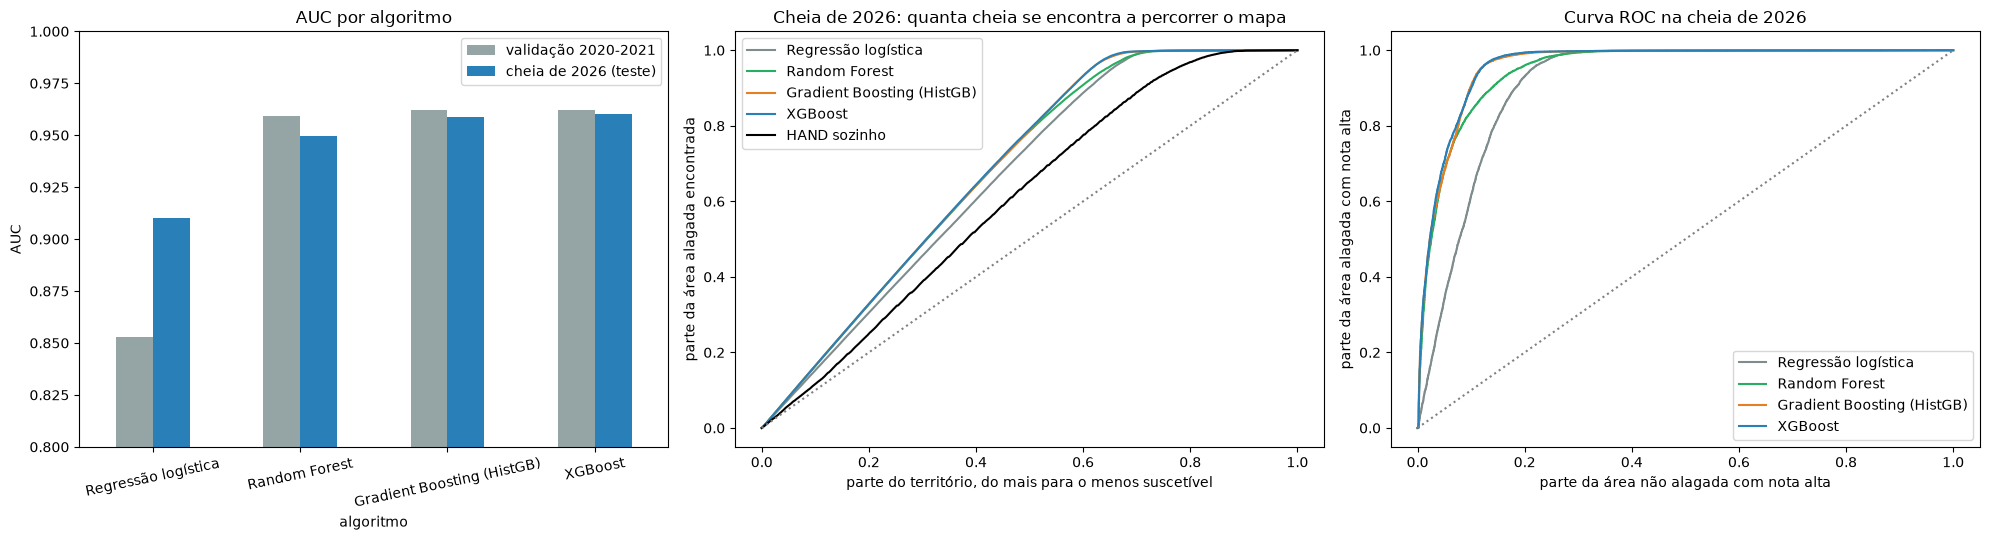

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
algorithms[["auc_validacao_2020_21", "auc_cheia_2026"]].plot.bar(ax=axes[0], color=["#95a5a6", "#2980b9"], rot=12)
axes[0].set_ylim(0.8, 1.0); axes[0].set_ylabel("AUC"); axes[0].set_title("AUC por algoritmo"); axes[0].legend(["validação 2020-2021", "cheia de 2026 (teste)"])
for name in algorithms.index:
    plots.capture_curve(axes[1], event["label_water"], p_event[name], event["weight"], label=name, colour=plots.COLOURS.get(name))
plots.capture_curve(axes[1], event["label_water"], -event["hand"], event["weight"], label="HAND sozinho", colour="black")
axes[1].plot([0, 1], [0, 1], color="grey", linestyle=":"); axes[1].legend(); axes[1].set_title("Cheia de 2026: quanta cheia se encontra a percorrer o mapa")
from sklearn.metrics import roc_curve
for name in algorithms.index:
    fpr, tpr, _ = roc_curve(event["label_water"], p_event[name], sample_weight=event["weight"])
    axes[2].plot(fpr, tpr, label=name, color=plots.COLOURS.get(name))
axes[2].plot([0, 1], [0, 1], color="grey", linestyle=":"); axes[2].legend(); axes[2].set_title("Curva ROC na cheia de 2026")
axes[2].set_xlabel("parte da área não alagada com nota alta"); axes[2].set_ylabel("parte da área alagada com nota alta")
plt.tight_layout(); plt.savefig(REPORTS / "31_modelo_a_algoritmos.png", dpi=110)

**Como ler os gráficos**

- **Esquerda:** AUC de cada algoritmo, na validação (cinzento) e no teste (azul).
- **Centro (curva de captura):** imagina percorrer o território do sítio com nota
  mais alta para o mais baixo. A curva mostra que parte da cheia de 2026 já foi
  encontrada. Uma curva que sobe depressa = o mapa põe a cheia nos sítios certos.
  A linha pontilhada seria um mapa ao acaso.
- **Direita:** curva ROC na cheia de 2026.

**O que a comparação mostra:** a regressão logística fica atrás; os modelos de
árvores ficam próximos entre si. Tal como no Modelo B, o algoritmo importa menos
do que os dados que lhe são dados.

## 4. Modelo final, importância das features e mapa

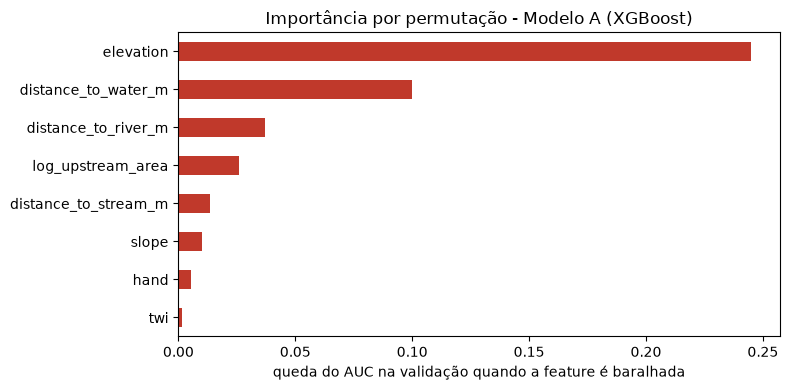

In [6]:
model = M.fit_model_a(cfg, table, M.TERRAIN_A, "modelo_a_terreno", make=M.algorithms()[BEST])
sample = val.sample(30000, random_state=0)
imp = M.importance(model, M.TERRAIN_A, M._x(sample, M.TERRAIN_A), sample["label_flood"], sample["weight"])
ax = imp.sort_values().plot.barh(figsize=(8, 4), title=f"Importância por permutação - Modelo A ({BEST})", color="#c0392b")
ax.set_xlabel("queda do AUC na validação quando a feature é baralhada")
plt.tight_layout(); plt.savefig(REPORTS / "31_modelo_a_importancia.png", dpi=110)

O rio e as lagoas (água permanente) ficam numa classe à parte: não são "zona de
cheia", já são água. A nota do resto do terreno é dividida em quatro classes,
por posição entre todos os píxeis de terra: **baixa** (a metade com notas mais
baixas), **média** (os 30 % seguintes), **alta** (15 %) e **muito alta** (os 5 % com
nota mais alta).

data/processed/maps/modelo_a/suscetibilidade_marracuene_30m.tif


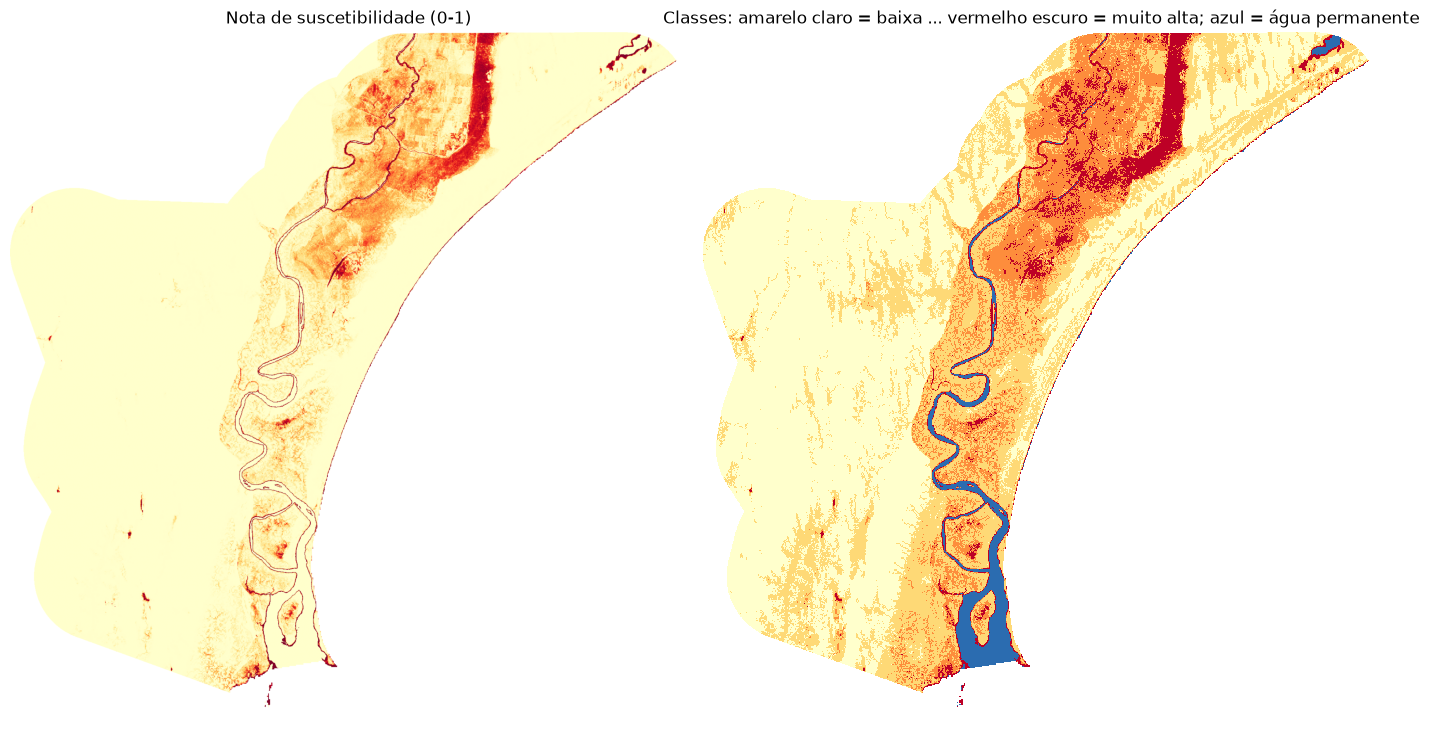

In [7]:
map_file = M.susceptibility_map(cfg, model, M.TERRAIN_A)
layers = rasters.read_bands(map_file)
names = {1: "baixa", 2: "média", 3: "alta", 4: "muito alta"}

from matplotlib.colors import ListedColormap
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
axes[0].imshow(layers["suscetibilidade"], cmap="YlOrRd", vmin=0, vmax=1); axes[0].set_title("Nota de suscetibilidade (0-1)"); axes[0].axis("off")
axes[1].imshow(layers["classe"], cmap=ListedColormap(["#2b6cb0", "#ffffcc", "#fed976", "#fd8d3c", "#bd0026"]), vmin=0, vmax=4, interpolation="nearest")
axes[1].set_title("Classes: amarelo claro = baixa ... vermelho escuro = muito alta; azul = água permanente"); axes[1].axis("off")
plt.tight_layout(); plt.savefig(REPORTS / "31_modelo_a_mapa.png", dpi=110)
print(map_file.relative_to(ROOT))

## 5. O mapa acerta? Teste com a cheia de janeiro de 2026

Para cada classe: que parte dela alagou em 2026, e que parte de toda a área
alagada caiu nessa classe. Só conta a área analisada pelo Copernicus.

,area_com_referencia_km2,parte_da_classe_que_alagou,parte_da_cheia_nesta_classe
baixa,110.027,0.003,0.001
média,179.708,0.565,0.352
alta,153.796,0.955,0.508
muito alta,40.691,0.984,0.139


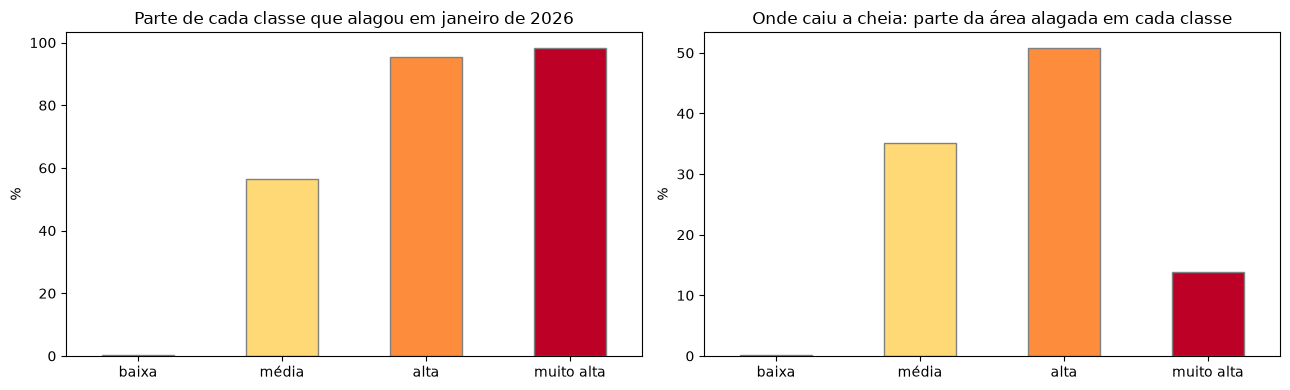

In [8]:
reference = M.reference_raster(cfg, "2026-01", res=30)
labelled = (reference > 0) & np.isfinite(layers["classe"])
flooded = reference == 2
test = pd.DataFrame({
    "area_com_referencia_km2": [((layers["classe"] == k) & labelled).sum() * 900 / 1e6 for k in names],
    "parte_da_classe_que_alagou": [flooded[(layers["classe"] == k) & labelled].mean() for k in names],
    "parte_da_cheia_nesta_classe": [((layers["classe"] == k) & labelled & flooded).sum() / (labelled & flooded).sum() for k in names],
}, index=list(names.values()))
test.round(3).to_csv(REPORTS / "31_modelo_a_teste_2026.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
colours = ["#ffffcc", "#fed976", "#fd8d3c", "#bd0026"]
(100 * test["parte_da_classe_que_alagou"]).plot.bar(ax=axes[0], color=colours, edgecolor="grey", rot=0, ylabel="%", title="Parte de cada classe que alagou em janeiro de 2026")
(100 * test["parte_da_cheia_nesta_classe"]).plot.bar(ax=axes[1], color=colours, edgecolor="grey", rot=0, ylabel="%", title="Onde caiu a cheia: parte da área alagada em cada classe")
plt.tight_layout(); plt.savefig(REPORTS / "31_modelo_a_teste_2026.png", dpi=110)
test

**Como ler.** Um bom mapa tem o gráfico da esquerda a subir de "baixa" para "muito
alta", e quase nada da cheia na classe "baixa".

A classe "média" também alagou em grande parte: janeiro de 2026 foi a maior
cheia dos 20 anos e cobriu cerca de um terço do distrito. Numa cheia normal, a
água fica sobretudo nas classes "alta" e "muito alta".

## As métricas são boas? Leitura de especialista

- **Um AUC perto de 0,95 numa cheia que o modelo nunca viu é um bom resultado.**
  Estudos de suscetibilidade costumam publicar valores entre 0,85 e 0,95, muitas
  vezes medidos em pontos sorteados dos mesmos eventos usados no treino, o que
  os torna otimistas. Aqui o teste é de outro ano e de outra fonte.
- **O número que mais interessa a quem decide** não é o AUC, é a tabela por
  classes: quase nada alagou na classe "baixa" e quase tudo na "alta" e "muito
  alta". É isso que torna o mapa utilizável para priorizar zonas.
- **O limite está nos dados, não no algoritmo:** os quatro algoritmos de árvores
  dão resultados parecidos. Para melhorar seria preciso um modelo de elevação
  mais fino (o atual é de 30 m) e mais cheias com referência.

## Limites do Modelo A

- **Diz onde, não quando.** É um mapa fixo. Não muda com a chuva.
- **Aprendeu com água sazonal e poucas cheias.** Os rótulos JRC veem mal as cheias
  (nuvens). O teste de 2026 mostra que, mesmo assim, o mapa ordena bem o risco.
- **Terreno a 30 m com dados de 30–90 m.** Diques, valas e aterros pequenos não
  aparecem no modelo de elevação; ruas e bairros concretos podem estar mal
  classificados. O mapa serve para planear por zonas, não casa a casa.
- **Um só evento de teste**, e só na parte do distrito analisada pelo Copernicus.